# Mobile Game In-App Purchases — Data Analytics

### Player Spending Behavior, Revenue Analysis & Business Insights

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Business Objective

### Business Objective

This project analyzes mobile game in-app purchase data to better understand player spending behavior and revenue distribution.

The analysis explores how spending patterns differ across player segments, age groups, countries, and game genres.

The goal is to identify key revenue drivers, highlight potential business risks, and provide data-driven recommendations to support player retention and monetization strategies.

## Data Overview

The dataset contains 3,024 rows and 13 columns describing player demographics, gaming activity, and in-app purchases. 

In [2]:
df = pd.read_csv('data/mobile_game_inapp_purchases.csv')
df.head()

,UserID,Age,Gender,Country,Device,GameGenre,SessionCount,AverageSessionLength,SpendingSegment,InAppPurchaseAmount,FirstPurchaseDaysAfterInstall,PaymentMethod,LastPurchaseDate
0,c9889ab0-9cfc-4a75-acd9-5eab1df0015c,49.0,Male,Norway,Android,Battle Royale,9,12.83,Minnow,11.40,28.0,Apple Pay,2025-03-19
1,7c9e413c-ecca-45f2-a780-2826a07952a2,15.0,Male,Switzerland,iOS,Action RPG,11,19.39,Minnow,6.37,18.0,Debit Card,2025-06-08
2,fd61e419-1a92-4f43-a8c7-135842ad328a,23.0,Male,China,Android,Fighting,9,8.87,Minnow,15.81,30.0,Apple Pay,2025-06-02
3,bdb7f6d1-ff9a-468c-afe7-43f32a94293e,31.0,Male,Mexico,Android,Racing,12,19.56,Minnow,13.49,9.0,Debit Card,2025-04-01
4,aa7eec14-4846-47b9-b879-9c98038cda04,37.0,Female,India,Android,Battle Royale,10,15.23,Minnow,10.86,15.0,Paypal,2025-05-05


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3024 entries, 0 to 3023
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   UserID                         3024 non-null   object 
 1   Age                            2964 non-null   float64
 2   Gender                         2964 non-null   object 
 3   Country                        2964 non-null   object 
 4   Device                         2964 non-null   object 
 5   GameGenre                      2964 non-null   object 
 6   SessionCount                   3024 non-null   int64  
 7   AverageSessionLength           3024 non-null   float64
 8   SpendingSegment                3024 non-null   object 
 9   InAppPurchaseAmount            2888 non-null   float64
 10  FirstPurchaseDaysAfterInstall  2888 non-null   float64
 11  PaymentMethod                  2888 non-null   object 
 12  LastPurchaseDate               2888 non-null   o

In [4]:
df.isna().sum()

UserID                             0
Age                               60
Gender                            60
Country                           60
Device                            60
GameGenre                         60
SessionCount                       0
AverageSessionLength               0
SpendingSegment                    0
InAppPurchaseAmount              136
FirstPurchaseDaysAfterInstall    136
PaymentMethod                    136
LastPurchaseDate                 136
dtype: int64

In [5]:
df[df.duplicated(keep=False)]

,UserID,Age,Gender,Country,Device,GameGenre,SessionCount,AverageSessionLength,SpendingSegment,InAppPurchaseAmount,FirstPurchaseDaysAfterInstall,PaymentMethod,LastPurchaseDate


## Data Cleaning

### Missing Values and Data Quality

The dataset contains missing values in demographic and purchase-related columns.

A total of 136 players have missing purchase information across four purchase-related fields: 111 Minnows, 20 Dolphins, and 5 Whales.

Missing purchase amounts were preserved rather than replaced with zero, since missing information does not necessarily indicate zero spending.

Of the 68 players classified as Whales, only 63 have recorded purchase amounts.

Calculations involving purchase amounts use available recorded values. Player counts may still include players with missing purchase amounts.

No fully duplicated rows were identified.

The original spending-segment classification criteria, data collection period, and precise definition of purchase amounts are not verified.

## Feature Engineering

In [6]:
df['Age_group'] = pd.cut(df['Age'], bins=[12,17,24,34,44,54], labels=['13-17','18-24','25-34','35-44','45-54'])

In [7]:
df['Age_group'].value_counts(dropna=False)

Age_group
25-34    725
35-44    711
45-54    702
18-24    495
13-17    331
NaN       60
Name: count, dtype: int64

## EDA

### Revenue Concentration by Spending Segment

In [8]:
spent = df.groupby('SpendingSegment').agg({
    'InAppPurchaseAmount' : ['mean','sum'],
    'UserID' : 'count'
})
spent 

InAppPurchaseAmount            UserID
                               mean        sum  count
SpendingSegment                                      
Dolphin                  245.634694   96288.80    412
Minnow                    10.023580   24387.37   2544
Whale                   2787.033968  175583.14     68

In [9]:
spent['Revenue Share (%)'] = (spent[('InAppPurchaseAmount', 'sum')] / spent[('InAppPurchaseAmount', 'sum')].sum()) * 100
spent

InAppPurchaseAmount            UserID Revenue Share (%)
                               mean        sum  count                  
SpendingSegment                                                        
Dolphin                  245.634694   96288.80    412         32.501527
Minnow                    10.023580   24387.37   2544          8.231765
Whale                   2787.033968  175583.14     68         59.266708

### Dolphin Revenue by Age Group

In [10]:
dolphin_by_age = (df[df['SpendingSegment'] == 'Dolphin'].groupby('Age_group', observed=True).agg(
        Player_Count=('UserID', 'count'),
        Recorded_Purchases=('InAppPurchaseAmount', 'count'),
        Total_Revenue=('InAppPurchaseAmount', 'sum'),
        Average_Revenue=('InAppPurchaseAmount', 'mean')))

display(dolphin_by_age.round(2))

,Player_Count,Recorded_Purchases,Total_Revenue,Average_Revenue
Age_group,,,,
13-17,46,45,11159.09,247.98
18-24,58,54,11809.46,218.69
25-34,105,99,24744.93,249.95
35-44,110,106,24989.89,235.75
45-54,88,84,21953.55,261.35


### Dolphin vs Whale Distribution by Game Genre

In [11]:
high_spender = df[df['SpendingSegment'].isin(['Dolphin', 'Whale'])]

In [12]:
game_genre = high_spender.groupby(['GameGenre', 'SpendingSegment']).agg({
    'UserID' : 'count'
})
game_genre

UserID
GameGenre     SpendingSegment        
Action RPG    Dolphin              24
              Whale                 4
Adventure     Dolphin              39
              Whale                 1
Battle Royale Dolphin              25
              Whale                 7
Card          Dolphin              20
              Whale                 3
Casual        Dolphin              24
              Whale                 6
Fighting      Dolphin              33
              Whale                 4
MMORPG        Dolphin              29
              Whale                 3
MOBA          Dolphin              23
              Whale                 5
Puzzle        Dolphin              21
              Whale                 4
Racing        Dolphin              30
              Whale                 8
Role Playing  Dolphin              24
              Whale                 4
Sandbox       Dolphin              29
              Whale                 3
Simulation    Dolphin              30
              Whale                 4
Sports        Dolphin              29
              Whale                 3
Strategy      Dolphin              23
              Whale                 8

### Afghanistan Revenue by Spending Segment

In [13]:
afghan_df = df[df['Country'] == 'Afghanistan']

In [14]:
group_spending = afghan_df.groupby('SpendingSegment').agg({
    'UserID' : 'count',
    'InAppPurchaseAmount' : 'sum'
})
group_spending

,UserID,InAppPurchaseAmount
SpendingSegment,,
Dolphin,18,5664.53
Minnow,71,672.82
Whale,4,14368.72


### Engagement vs Spending Segment

In [15]:
table = df.groupby('SpendingSegment').agg({
    'SessionCount' : 'mean',
    'AverageSessionLength' : 'mean'
})
table

,SessionCount,AverageSessionLength
SpendingSegment,,
Dolphin,10.123786,20.035704
Minnow,10.044025,20.137445
Whale,10.926471,17.931471


## Genre Performance Analysis

In [16]:
genre_performance = df.groupby('GameGenre').agg(Total_Players=('UserID', 'count'), Total_Revenue=('InAppPurchaseAmount', 'sum'),
    Average_Revenue=('InAppPurchaseAmount', 'mean'))

whale_count = (df[df['SpendingSegment'] == 'Whale'].groupby('GameGenre')['UserID'].count())
genre_performance['Whale_Count'] = whale_count

genre_performance['Whale_Count'] = (genre_performance['Whale_Count'].fillna(0).astype(int))
genre_performance['Whale_Rate_Pct'] = (genre_performance['Whale_Count'] / genre_performance['Total_Players'] * 100)
genre_performance = genre_performance.sort_values(by='Total_Revenue',ascending=False)

display(genre_performance.round(2))

,Total_Players,Total_Revenue,Average_Revenue,Whale_Count,Whale_Rate_Pct
GameGenre,,,,,
Racing,191,29163.56,160.24,8,4.19
Battle Royale,189,28046.79,156.69,7,3.70
Strategy,198,27066.62,143.21,8,4.04
MOBA,181,24190.19,139.83,5,2.76
Fighting,181,24177.92,140.57,4,2.21
MMORPG,198,18444.36,98.11,3,1.52
Simulation,219,17804.21,84.78,4,1.83
Role Playing,193,17030.56,93.06,4,2.07
Card,202,16392.15,84.06,3,1.49


## country_analysis

In [17]:
country_analysis = df.groupby('Country').agg(Total_Players=('UserID', 'count'), Total_Revenue=('InAppPurchaseAmount', 'sum'))

whale_country = (df[df['SpendingSegment'] == 'Whale'].groupby('Country').agg(Whale_Count=('UserID', 'count'),
        Whale_Revenue=('InAppPurchaseAmount', 'sum')))

country_analysis = country_analysis.join(whale_country)

country_analysis[['Whale_Count', 'Whale_Revenue']] = (country_analysis[['Whale_Count', 'Whale_Revenue']].fillna(0))

country_analysis['Whale_Revenue_Share_Pct'] = (country_analysis['Whale_Revenue'] / country_analysis['Total_Revenue'].replace(0, float('nan'))* 100)

country_analysis = country_analysis.sort_values(by='Whale_Revenue_Share_Pct',ascending=False)
display(country_analysis.round(2))

,Total_Players,Total_Revenue,Whale_Count,Whale_Revenue,Whale_Revenue_Share_Pct
Country,,,,,
South Korea,103,14115.99,5.0,11287.26,79.96
Canada,105,14358.44,4.0,11118.29,77.43
Italy,112,13549.10,4.0,10336.35,76.29
Denmark,106,13901.79,3.0,10396.30,74.78
Afghanistan,93,20706.07,4.0,14368.72,69.39
Russia,93,12967.70,3.0,8995.78,69.37
Iran,105,11647.15,5.0,8050.37,69.12
Germany,114,13555.49,5.0,9344.21,68.93
Bangladesh,101,17087.77,4.0,11683.35,68.37


## engagement_analysis

In [18]:
engagement_analysis = df.groupby('SpendingSegment').agg(
    Player_Count=('UserID', 'count'),
    Avg_Sessions=('SessionCount', 'mean'),
    Std_Sessions=('SessionCount', 'std'),
    Avg_Session_Length=('AverageSessionLength', 'mean'),
    Std_Session_Length=('AverageSessionLength', 'std')
)

display(engagement_analysis.round(2))

,Player_Count,Avg_Sessions,Std_Sessions,Avg_Session_Length,Std_Session_Length
SpendingSegment,,,,,
Dolphin,412,10.12,3.18,20.04,8.50
Minnow,2544,10.04,3.10,20.14,8.59
Whale,68,10.93,3.34,17.93,8.59


## Data Visualization

### Revenue Distribution by Spending Segment

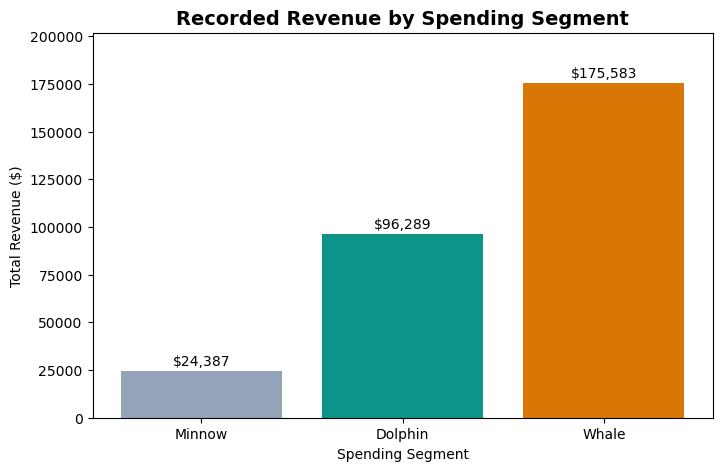

In [19]:
spent = spent.reindex(['Minnow', 'Dolphin', 'Whale'])

segments = spent.index
revenue = spent[('InAppPurchaseAmount', 'sum')]


colors = ['#94A3B8', '#0D9488', '#D97706']
plt.figure(figsize=(8, 5))
plt.bar(segments, revenue, color=colors)

plt.title('Recorded Revenue by Spending Segment', fontsize=14, fontweight='bold')
plt.xlabel('Spending Segment')
plt.ylabel('Total Revenue ($)')

for i, value in enumerate(revenue):
    plt.text(i, value + 3000, f'${value:,.0f}', ha='center')
plt.ylim(0, max(revenue) * 1.15)

plt.show()

### Dolphin Revenue by Age Group

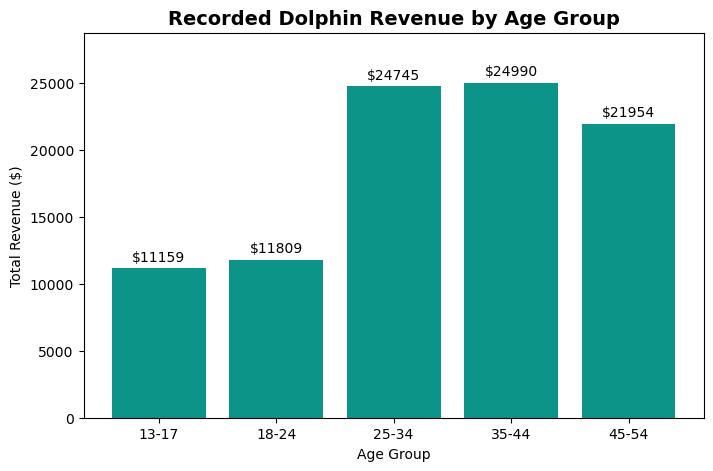

In [20]:
age_groups = dolphin_by_age.index
revenue_by_age = dolphin_by_age['Total_Revenue']

plt.figure(figsize=(8, 5))
bars = plt.bar(age_groups, revenue_by_age, color='#0D9488')
plt.bar_label(bars, fmt='$%.0f', padding=3)

plt.title('Recorded Dolphin Revenue by Age Group',
          fontsize=14, fontweight='bold')
plt.xlabel('Age Group')
plt.ylabel('Total Revenue ($)')
plt.ylim(0, max(revenue_by_age) * 1.15)

plt.show()

### Average Sessions by Spending Segment

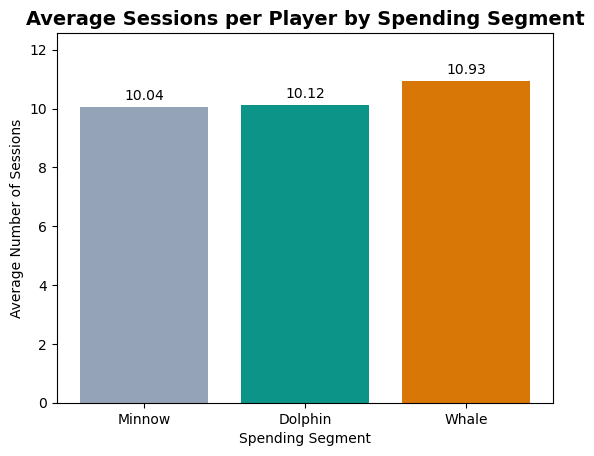

In [21]:
table = table.reindex(['Minnow', 'Dolphin', 'Whale'])
spending_segments = table.index
average_sessions = table['SessionCount']

colors = ['#94A3B8', '#0D9488', '#D97706']
bars = plt.bar(spending_segments, average_sessions, color=colors)
plt.bar_label(bars, fmt='%.2f', padding=3)

plt.title('Average Sessions per Player by Spending Segment',
          fontsize=14, fontweight='bold')

plt.xlabel('Spending Segment')
plt.ylabel('Average Number of Sessions')

plt.ylim(0, max(average_sessions) * 1.15)
plt.show()

### Average Session Length by Spending Segment

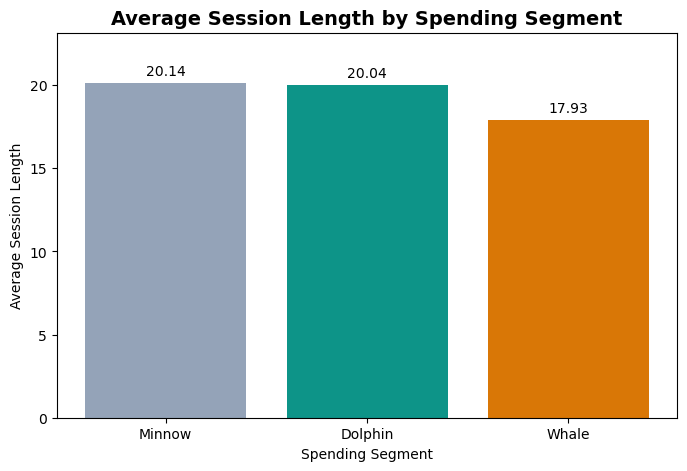

In [22]:
table = table.reindex(['Minnow', 'Dolphin', 'Whale'])

spending_segments = table.index
average_session_length = table['AverageSessionLength']

colors = ['#94A3B8', '#0D9488', '#D97706']

plt.figure(figsize=(8, 5))

bars = plt.bar(spending_segments, average_session_length, color=colors)
plt.bar_label(bars, fmt='%.2f', padding=3)
plt.title('Average Session Length by Spending Segment', fontsize=14, fontweight='bold')

plt.xlabel('Spending Segment')
plt.ylabel('Average Session Length')

plt.ylim(0, max(average_session_length) * 1.15)

plt.show()

## Business Insights & Recommendations

### 1. Revenue Concentration

**Finding:** Of the 3,024 players, 68 (2.25%) are classified as Whales. Only 63 of these players have recorded purchase amounts. The Whale segment accounts for approximately 59.3% of total recorded revenue (USD 175,583 out of USD 296,259).

**Business Insight:** Revenue is highly concentrated among a small group of high-spending players, creating potential revenue concentration risk.

**Recommendation:** Evaluate targeted retention initiatives for high-value players and assess their effectiveness before committing additional resources.

### 2. Dolphin Revenue by Age Group

**Finding:** Dolphin players aged 25–44 generate USD 49,734.82, approximately 51.65% of total recorded Dolphin revenue. The highest average recorded revenue per Dolphin with a known purchase amount is observed in the 45–54 age group (USD 261.35).

**Business Insight:** Higher total revenue among Dolphins aged 25–44 does not necessarily indicate higher individual spending. Group size is an important factor, and the average recorded spending varies across age groups.

**Recommendation:** Compare player counts, recorded revenue per player, acquisition costs, and retention across age groups before allocating marketing resources. The current data does not establish which age group would deliver the highest return on marketing investment.

### 3. Game Genre Distribution

**Finding:** Racing, Battle Royale, and Strategy generate the highest recorded revenue among the 15 game genres (USD 29,163.56, USD 28,046.79, and USD 27,066.62, respectively). Their Whale player rates are 4.19%, 3.70%, and 4.04%, compared with approximately 2.25% across the full dataset.

**Business Insight:** The three highest-revenue genres also have relatively high proportions of Whale players. However, the number of Whales within each genre is small, and these descriptive results do not establish that game genre causes higher spending.

**Recommendation:** Further investigate revenue per player, spending patterns, and the stability of high-spender rates across genres before prioritizing game development or marketing investments. Additional data on development costs and player retention would be needed to assess business value.

### 4. Revenue Concentration Across Countries

**Finding:** In the five countries with the highest recorded Whale revenue shares, Whale players account for approximately 69%–80% of each country's recorded revenue. South Korea has the highest share (79.96%), followed by Canada (77.43%), Italy (76.29%), Denmark (74.78%), and Afghanistan (69.39%). Each country has only 3–5 Whale players.

**Business Insight:** Revenue concentration among Whale players is observed across multiple countries, rather than being unique to Afghanistan. However, the small number of Whales per country makes these percentages sensitive to individual player spending.

**Recommendation:** Monitor revenue concentration and evaluate the stability of high-value player spending across countries before making country-specific marketing or retention decisions. Additional time-based purchase and retention data would be required to assess actual revenue risk.

### 5. Engagement vs Spending

**Finding:** Whale players average 10.93 sessions compared with 10.12 for Dolphins and 10.04 for Minnows. Their average session length is 17.93, compared with 20.04 for Dolphins and 20.14 for Minnows. Standard deviations are approximately 3.1–3.3 for session counts and 8.5–8.6 for session lengths, indicating substantial within-group variability relative to the differences in group averages.

**Business Insight:** Although engagement averages differ slightly between spending segments, these descriptive statistics alone do not establish whether engagement metrics reliably predict player spending or whether increasing engagement would cause higher revenue.

**Recommendation:** Investigate player-level relationships between engagement and recorded spending, including correlations and distributional differences, before using session frequency or duration to guide monetization decisions. Additional longitudinal or experimental data would be needed to evaluate causal effects.